# Notebook 01: Thu thập và Khám phá Dữ liệu (Data Collection & Exploration)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) năm 2025 và Dự báo Mức độ Nghiêm trọng năm 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm:** Global Ban  
- Đinh Công Khang (24120332)
- Trần Ngô Uyên Nhi (24120210)
- Huỳnh Tuấn Kiệt (24120356)

In [1]:
import sys
import logging
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import các module trong src/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Bật log để thấy số dòng trước/sau mỗi bước (đề yêu cầu báo cáo row count)
logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", force=True)

from src.data_loader import build_consolidated_tables, load_processed
from src.visualization import set_project_plot_style
set_project_plot_style()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

---
## 1. Thu thập Dữ liệu (Data Collection — Mục 3.1)

### 1.1. Chủ đề & Bối cảnh thực tế (Subject & Real-world Context)
- **Chủ đề:** Báo cáo các biến cố/phản ứng bất lợi (Adverse Events — AE), thiếu hụt hiệu quả mong đợi (Lack of Expected Effectiveness) và lỗi chất lượng sản phẩm liên quan đến thuốc, chế phẩm sinh học và thiết bị dùng trong thú y.
- **Bối cảnh thực tế:** Giám sát cảnh giác dược thú y hậu mại (Post-market Veterinary Pharmacovigilance) giúp cơ quan quản lý (FDA CVM), bác sĩ thú y lâm sàng, hãng dược và người nuôi thú cưng/gia súc nhận diện sớm các tín hiệu rủi ro an toàn thuốc theo loài, giai đoạn tuổi, cân nặng, đường dùng và hoạt chất.

### 1.2. Tác giả, Nguồn gốc, Quần thể & Phạm vi thời gian (Author, Provenance, Population & Period)
- **Tác giả / Tổ chức thu thập & phát hành:** **U.S. Food and Drug Administration (FDA) – Center for Veterinary Medicine (CVM)** (trực thuộc Bộ Y tế và Dịch vụ Nhân sinh Hoa Kỳ — HHS). Dữ liệu xuất phát từ hệ thống cơ sở dữ liệu quốc gia **CVM Adverse Drug Experience (ADE)** và được chuẩn hóa, phân phối qua nền tảng **openFDA** (`animalandveterinary/event`).
- **Cổng tải & Manifest chính thức:**
  - Trang tải dữ liệu hàng loạt: [openFDA Animal & Veterinary Adverse Events Downloads](https://open.fda.gov/data/downloads/)
  - Manifest JSON (chứa đường dẫn phân vùng quý, `export_date`, số bản ghi): [`https://api.fda.gov/download.json`](https://api.fda.gov/download.json)
  - Đặc tả Schema & API: [openFDA Animal & Veterinary API Documentation](https://open.fda.gov/apis/animalandveterinary/event/)
- **Quần thể & Đơn vị quan sát (Population & Unit of Observation):**
  - *Quần thể mục tiêu:* Các trường hợp động vật (thú cưng như Chó, Mèo; ngựa; gia súc, gia cầm và các loài khác) sử dụng thuốc/chế phẩm thú y (chủ yếu lưu hành tại Hoa Kỳ hoặc do nhà sản xuất đăng ký với FDA báo cáo) gặp sự cố bất lợi hoặc kém hiệu quả và được gửi báo cáo về FDA CVM.
  - *Đơn vị quan sát:* Mỗi bản ghi (`unique_aer_id_number`) đại diện cho **1 báo cáo sự kiện bất lợi (Adverse Event Report)** — thường ứng với 1 cá thể bệnh (ở thú cưng) hoặc 1 đàn/nhóm vật nuôi được điều trị cùng lúc (`number_of_animals_affected > 1` ở vật nuôi trang trại).
- **Phạm vi thời gian sử dụng trong đồ án (5 phân vùng quý liên tiếp `2025q1` – `2026q1`):**
  - **Tập lịch sử & huấn luyện (2025 Q1 – Q4):** Toàn bộ 4 phân vùng quý của năm 2025 (`2025q1`–`2025q4`), dùng để phân tích chuyên sâu Q1–Q5 và huấn luyện/kiểm định chéo mô hình Học máy (Q6).
  - **Tập kiểm thử tương lai / Out-of-Time Test (2026 Q1):** Phân vùng quý đầu năm 2026 (`2026q1`), giữ độc lập để đối chiếu sự dịch chuyển xu hướng (*data/concept drift*) và đánh giá khả năng dự báo thực tế của mô hình học máy.

### 1.3. Xác minh Giấy phép & Điều khoản sử dụng (License Verification & Terms)
- **License:** **Creative Commons CC0 1.0 Universal (Public Domain Dedication)** — xác minh tại [https://open.fda.gov/license/](https://open.fda.gov/license/), trong trường `meta.license` của mỗi file JSON gốc, và toàn văn tại [https://creativecommons.org/publicdomain/zero/1.0/](https://creativecommons.org/publicdomain/zero/1.0/). Dữ liệu thuộc phạm vi công cộng, cho phép sao chép, chuẩn hóa và phân tích tự do.
- **Terms of Service & Disclaimer:** [https://open.fda.gov/terms/](https://open.fda.gov/terms/). Theo trường `meta.disclaimer` của openFDA: dữ liệu phản ánh thông tin như được báo cáo, FDA không tự động xác minh quan hệ nhân quả của từng ca riêng lẻ và dữ liệu không dùng để thay thế tư vấn y khoa/thú y lâm sàng.

### 1.4. Phương pháp thu thập & Các hạn chế/thiên lệch đã biết (Collection Method & Known Limitations/Biases)
- **Phương pháp thu thập (Giám sát Cảnh giác dược Thú y — 2 kênh thu thập):**
  1. **Báo cáo bắt buộc từ nhà sản xuất (Mandatory Reporting — 21 CFR 514.80):** Các hãng dược và nhà tài trợ thuốc thú y được cấp phép (NADA/ANADA) bắt buộc phải báo cáo các sự cố bất lợi về FDA CVM (báo cáo khẩn 15 ngày trên **Form FDA 1932** và báo cáo định kỳ) qua cổng điện tử **FDA Electronic Submissions Gateway (ESG / ESG NextGen — Electronic Submission System)** với chuẩn bản tin **HL7 ICSR** theo hướng dẫn quốc tế **VICH GL35** (*CVM GFI #214*).
  2. **Báo cáo tự nguyện từ thực tế lâm sàng (Voluntary / Spontaneous Reporting):** Bác sĩ thú y (`Veterinarian`), chủ vật nuôi (`Animal Owner`) và nhân viên y tế khác gửi báo cáo tự nguyện bằng cách báo cho hãng sản xuất (để hãng chuyển tiếp về FDA), hoặc gửi trực tiếp cho FDA CVM qua biểu mẫu PDF **Form FDA 1932a** hay bảng câu hỏi trực tuyến **Rational Questionnaire** trên cổng **Safety Reporting Portal (SRP)**.
  3. **Chuẩn hóa thuật ngữ chuyên ngành:** Các triệu chứng/phản ứng được chuẩn hóa theo bộ từ điển **VeDDRA** (*Veterinary Dictionary for Drug Regulatory Activities*) và thuốc được phân loại theo hệ thống **ATCvet** (WHO).
- **7 Hạn chế & Thiên lệch cốt lõi (Limitations & Known Biases):**
  1. **Thiếu mẫu số phơi nhiễm (Lack of Denominator / No Exposure Data):** Dữ liệu chỉ gồm các ca **có báo cáo sự cố**, không có tổng số cá thể động vật đã dùng thuốc an toàn $\rightarrow$ **không thể tính tỷ lệ mắc bệnh tuyệt đối (incidence rate / absolute risk)**, chỉ kết luận trên tỷ trọng báo cáo hoặc Tỷ số chênh báo cáo (*Reporting Odds Ratio — ROR*).
  2. **Không thiết lập quan hệ nhân quả trực tiếp (No Proof of Causality):** Sự xuất hiện đồng thời của thuốc và phản ứng trong báo cáo chỉ phản ánh sự kết hợp về mặt thời gian (*temporal association*), không chứng minh thuốc là nguyên nhân gây ra phản ứng (có thể nhiễu bởi bệnh nền, tuổi già, hoặc tương tác đa thuốc).
  3. **Báo cáo thiếu & Thiên lệch mức độ nghiêm trọng (Under-reporting & Severity/Stimulated Reporting Bias):** Không phải mọi phản ứng phụ ngoài thực tế đều được báo cáo; các biến cố nặng (`serious_ae = true`, tử vong), thuốc vừa mới cấp phép (*Weber effect*) hoặc thuốc có cảnh báo truyền thông thường được báo cáo với tần suất cao hơn.
  4. **Thiên lệch theo loài và hành vi người báo cáo (Species & Reporter Bias):** Thú cưng (Chó, Mèo) được theo dõi cá thể hóa nên chiếm tỷ trọng áp đảo so với vật nuôi trang trại (vốn thường báo cáo gộp theo đàn `number_of_animals_affected > 1`). Bác sĩ thú y (`Veterinarian`), Chủ vật nuôi (`Animal Owner`) và Hãng dược cũng khác biệt rõ rệt về độ đầy đủ lâm sàng và độ trễ gửi báo cáo (`reporting_delay_days`).
  5. **Khử trùng lặp phòng ngừa theo `unique_aer_id_number` & Phân biệt với `report_id` (Precautionary Deduplication & Identifier Distinction):** Về mặt lý thuyết, hồ sơ có thông tin bổ sung (follow-up) có thể được cập nhật lại với cùng mã `unique_aer_id_number`. Dù kiểm tra thực tế trên các cặp quý liền kề (`2025q1` $\leftrightarrow$ `2025q2`, `2025q4` $\leftrightarrow$ `2026q1`) ghi nhận `0` bản ghi trùng `unique_aer_id_number`, `src/data_loader.py` vẫn thực hiện **khử trùng lặp phòng ngừa** theo `unique_aer_id_number` (giữ bản ở quý/file muộn nhất). Tuyệt đối **không** dedupe theo `report_id`, vì `report_id` là mã đơn đăng ký thuốc NADA/ANADA (vd: `N141302`, `N141272`) dùng chung cho nhiều ca bệnh độc lập.
  6. **Dữ liệu khuyết không ngẫu nhiên & Đơn vị đo lường hỗn hợp (Missingness & Heterogeneous Units):** Định dạng JSON đa cấp (`drug[]`, `reaction[]`, `outcome[]`), nhiều trường tùy chọn bị khuyết theo cơ chế MAR/MNAR và đơn vị tuổi/cân nặng không đồng nhất (`Day/Week/Month/Year`, `lb/oz/g/kg`).
  7. **Độ trễ đăng tải & dữ liệu theo thời điểm tải (Posting Delay & Snapshot):** openFDA cập nhật theo quý và báo cáo có thể trễ 3–6 tháng kể từ lúc FDA nhận; hồ sơ cũng có thể được bổ sung sau đó. Vì vậy phân vùng `2026q1` là ảnh chụp tại thời điểm tải (`meta.last_updated` ghi trong `data/raw/MANIFEST.json`), có thể chưa đầy đủ hoặc thay đổi nếu tải lại về sau, ảnh hưởng đến phân tích độ trễ báo cáo (Q5) và tập test của Q6.

### 1.5. Công trình/Notebook công khai liên quan & Điểm khác biệt (Declare Existing Work & Differentiation)
- **Các công trình, tài liệu và repo công khai liên quan:**
  1. **Cổng khám phá tương tác chính thức của openFDA** ([openFDA Animal & Veterinary Interactive Chart](https://open.fda.gov/apis/animalandveterinary/event/explore-the-api-with-an-interactive-chart/)): Chỉ cung cấp thống kê đếm tần suất đơn biến (top loài, top người báo cáo, top phản ứng VeDDRA).
  2. **Kho mã nguồn hạ tầng, Thư viện AI Skills & Công cụ truy vấn trên GitHub** ([`FDA/openfda`](https://github.com/FDA/openfda), [`OpenVet-Projects/VetClaw`](https://github.com/OpenVet-Projects/VetClaw), [`api-evangelist/openfda`](https://github.com/api-evangelist/openfda)): Tập trung vào hạ tầng nạp dữ liệu backend (`FDA/openfda`), thư viện kỹ năng AI thú y có tích hợp SDK client cho openFDA (`OpenVet-Projects/VetClaw`), hoặc đặc tả API/wrapper tra cứu qua REST API (`api-evangelist/openfda`).
  3. **Nghiên cứu Học máy & XAI trên dữ liệu openFDA CVM** (Sholehrasa et al., 2025 — [`arXiv:2510.01520`](https://arxiv.org/abs/2510.01520), *"Predictive Modeling and Explainable AI for Veterinary Safety Profiles, Residue Assessment, and Health Outcomes Using Real-World Data and Physicochemical Properties"*): Kết hợp dữ liệu lịch sử 1987–2025Q1 với các đặc trưng hóa lý của thuốc lấy từ PubChem (khối lượng phân tử, XLogP3, số chất nhận liên kết hydro...) để phân loại kết cục hậu nghiệm (*Death vs. Recovery*).
  4. **Các nghiên cứu Cảnh giác dược thú y chuyên biệt** (Xu et al., 2019 — *Topics in Companion Animal Medicine*, 37:100366, [`doi:10.1016/j.tcam.2019.100366`](https://doi.org/10.1016/j.tcam.2019.100366); Farrell et al., 2025 — *Frontiers in Veterinary Science*, 12:1581490, [`doi:10.3389/fvets.2025.1581490`](https://doi.org/10.3389/fvets.2025.1581490)): Xu et al. (2019) phân tích dữ liệu openFDA CVM trên Chó và Mèo nhưng tập trung vào 2 hoạt chất trị ký sinh trùng đơn lẻ (*selamectin* và *spinosad*); Farrell et al. (2025) phân tích bất cân xứng các biến cố cơ xương khớp của kháng thể đơn dòng *bedinvetmab* so với 6 thuốc đối chứng trị viêm xương khớp ở chó trên cơ sở dữ liệu **EudraVigilance Veterinary (EVV)** của EMA (2004–2024).
- **Điểm khác biệt cốt lõi của đồ án nhóm Global Ban:**
  1. **Pipeline chuẩn hóa 4 bảng phẳng & khử trùng lặp phòng ngừa:** Thiết kế `src/download_data.py` và `src/data_loader.py` có kiểm tra toàn vẹn SHA-256 và loại trùng phòng ngừa theo `unique_aer_id_number` trên giai đoạn **2025 Q1–Q4 & 2026 Q1**.
  2. **Kiểm soát biến nhiễu (D4), định lượng bất định (D5) & kiểm tra độ vững (D6):** Đối chiếu *Safety Issue* vs. *Lack Of Expected Effectiveness* bằng ROR (Q3), đánh giá tương tác *Off-label $\times$ Polypharmacy* (Q4), và phân tích độ trễ báo cáo theo đối tượng gửi (Q5).
  3. **Dự báo Triage tại thời điểm tiếp nhận với kiểm thử ngoài thời gian (Out-of-Time Split):** Dự báo trực tiếp `serious_ae` (**Train 2025 Q1–Q4 $\rightarrow$ Out-of-Time Test 2026 Q1**), loại bỏ triệt để các biến rò rỉ hậu nghiệm (`outcome`, `treated_for_ae`, `duration`).

### 1.6. Lý do chọn bộ dữ liệu (Motivation)
- Độc đáo, mang tính ứng dụng liên ngành cao (Cảnh giác Dược Thú y & Khoa học Dữ liệu), quy mô lớn (hàng chục nghìn báo cáo qua 5 quý `2025q1`–`2026q1`) và cấu trúc JSON lồng nhau giúp thể hiện trọn vẹn kỹ năng làm phẳng (flatten/normalize), tiền xử lý đơn vị sinh học và thiết kế kiểm thử theo thời gian (Temporal Validation).

In [2]:
# TODO [Giai đoạn 1]: Đọc các file JSON (2025 Q1 - 2026 Q1) từ thư mục ../data/raw/
# và tách thành 4 bảng chuẩn hóa: reports_df, drugs_df, reactions_df, outcomes_df
# Chỉ build lại khi chưa có đủ 4 CSV (đổi REBUILD = True để ép chạy lại)
REBUILD = False
csv_ready = all((PROCESSED_DIR / f"{n}.csv").exists()
                for n in ("reports", "drugs", "reactions", "outcomes"))

if REBUILD or not csv_ready:
    reports_df, drugs_df, reactions_df, outcomes_df = build_consolidated_tables(
        raw_dir=RAW_DIR, processed_dir=PROCESSED_DIR
    )
else:
    tables = load_processed(PROCESSED_DIR)          # dtype=str, ép kiểu ở bước tiền xử lý
    reports_df, drugs_df, reactions_df, outcomes_df = (
        tables["reports"], tables["drugs"], tables["reactions"], tables["outcomes"]
    )

# Kiểm tra nhanh kích thước 4 bảng
for name, df in [("reports", reports_df), ("drugs", drugs_df),
                 ("reactions", reactions_df), ("outcomes", outcomes_df)]:
    print(f"{name:10s} {df.shape[0]:>9,} dòng × {df.shape[1]:>3} cột")

# Số báo cáo theo quý (kiểm tra đủ 5 quý 2025q1–2026q1)
print()
print(reports_df["quarter"].value_counts().sort_index())

# Khóa liên kết phải không trùng ở reports
assert reports_df["unique_aer_id_number"].is_unique, "reports còn unique_aer_id_number trùng!"

# Mọi dòng ở bảng con phải có báo cáo cha (không có khóa mồ côi)
for name, df in [("drugs", drugs_df), ("reactions", reactions_df), ("outcomes", outcomes_df)]:
    orphan = (~df["unique_aer_id_number"].isin(reports_df["unique_aer_id_number"])).sum()
    print(f"{name}: {orphan} dòng không có báo cáo cha")

reports       94,412 dòng ×  33 cột
drugs        174,123 dòng ×  31 cột
reactions    270,244 dòng ×   8 cột
outcomes      85,143 dòng ×   5 cột

quarter
2025q1    16458
2025q2    21732
2025q3    20843
2025q4    18072
2026q1    17307
Name: count, dtype: int64
drugs: 0 dòng không có báo cáo cha
reactions: 0 dòng không có báo cáo cha
outcomes: 0 dòng không có báo cáo cha


---
## 2. Khám phá Dữ liệu (Data Exploration — Mục 3.2)

### 2.1. Tổng quan cấu trúc & Schema (Overview)
- Kiểm tra số dòng, số cột của từng bảng sau khi flatten (`reports`, `drugs`, `reactions`, `outcomes`) qua từng quý (2025 Q1–Q4 vs. 2026 Q1).
- Ý nghĩa một dòng ở mỗi bảng, khóa liên kết duy nhất `unique_aer_id_number` và sự khác biệt với `report_id` (mã đơn đăng ký thuốc NADA/ANADA).
- Kiểm tra các bản ghi trùng lặp (`duplicated`) hoặc rỗng và nêu rõ lý do giữ/loại bỏ.

In [ ]:
# TODO [Giai đoạn 2]: Thống kê kích thước bảng, kiểu dữ liệu và kiểm tra duplicate theo unique_aer_id_number


### 2.2. Khám phá các biến số (Numerical Columns)
- Phân phối, trung tâm và độ phân tán của: tuổi vật nuôi (`animal.age`), cân nặng (`animal.weight`), số lượng cá thể bị ảnh hưởng (`number_of_animals_affected`), độ trễ báo cáo (`reporting_delay_days`), số thuốc dùng kèm (`num_drugs`).
- Phát hiện giá trị ngoại lai (IQR, Z-score) và các giá trị vô lý/placeholder (tuổi âm, cân nặng = 0 hoặc cực đại bất thường) kèm hướng xử lý.

In [ ]:
# TODO [Giai đoạn 2]: Phân tích thống kê mô tả và trực quan hóa phân phối biến số (sau khi quy đổi đơn vị)


### 2.3. Khám phá các biến phân loại (Categorical Columns)
- Kiểm tra số lượng giá trị phân biệt và tần suất của: `animal.species`, `animal.gender`, `primary_reporter`, `type_of_information`, `serious_ae`, `treated_for_ae`, `drug.route`, `drug.used_according_to_label`, `reaction.veddra_term_name`, `outcome.medical_status`.
- Phát hiện nhãn không nhất quán (in hoa/thường, từ đồng nghĩa) và gom nhóm các danh mục hiếm (`Other`).

=== TỔNG QUAN BIẾN PHÂN LOẠI CẤP BÁO CÁO (REPORTS) ===


,Tên cột,Số giá trị duy nhất (Cardinality),Giá trị phổ biến nhất (Mode),Tần suất Mode,Tỷ lệ Mode (%),Số lượng khuyết (NaN),Tỷ lệ khuyết (%)
0,species,51,Dog,"66,103",70.02%,"9,777",10.36%
1,gender,4,Male,"39,599",41.94%,"9,798",10.38%
2,primary_reporter,7,Other Health Care Professional,"26,453",28.02%,2,0.00%
3,type_of_information,11,Safety Issue,"46,603",49.36%,5,0.01%
4,serious_ae,2,false,"48,855",51.75%,"10,106",10.70%
5,treated_for_ae,2,true,"40,892",43.31%,"23,567",24.96%



=== ĐỘ CÂN BẰNG NHÃN MỤC TIÊU (serious_ae Balance) ===


,Số lượng,Tỷ lệ (%)
serious_ae,,
false,48855,51.75
true,35451,37.55
NaN,10106,10.70



=== KIỂM TRA NHÃN KHÔNG NHẤT QUÁN (Inconsistent Labels) ===
- Cột species: Không phát hiện xung đột chữ hoa/thường hay khoảng trắng dư thừa.
- Cột gender: Không phát hiện xung đột chữ hoa/thường hay khoảng trắng dư thừa.
- Cột primary_reporter: Không phát hiện xung đột chữ hoa/thường hay khoảng trắng dư thừa.
- Cột type_of_information: Không phát hiện xung đột chữ hoa/thường hay khoảng trắng dư thừa.

=== CÁC DANH MỤC HIẾM TRONG SPECIES (< 1% -> Gom vào "Other") ===
Tổng số loài hiếm (< 1%): 48 loài (1,746 bản ghi, chiếm 1.85%)
Ví dụ 10 loài hiếm tiêu biểu: ['Cattle', 'Human', 'Pig', 'Chicken', 'Other', 'Goat', 'Rabbit', 'Ferret', 'Other Mammals', 'Sheep']


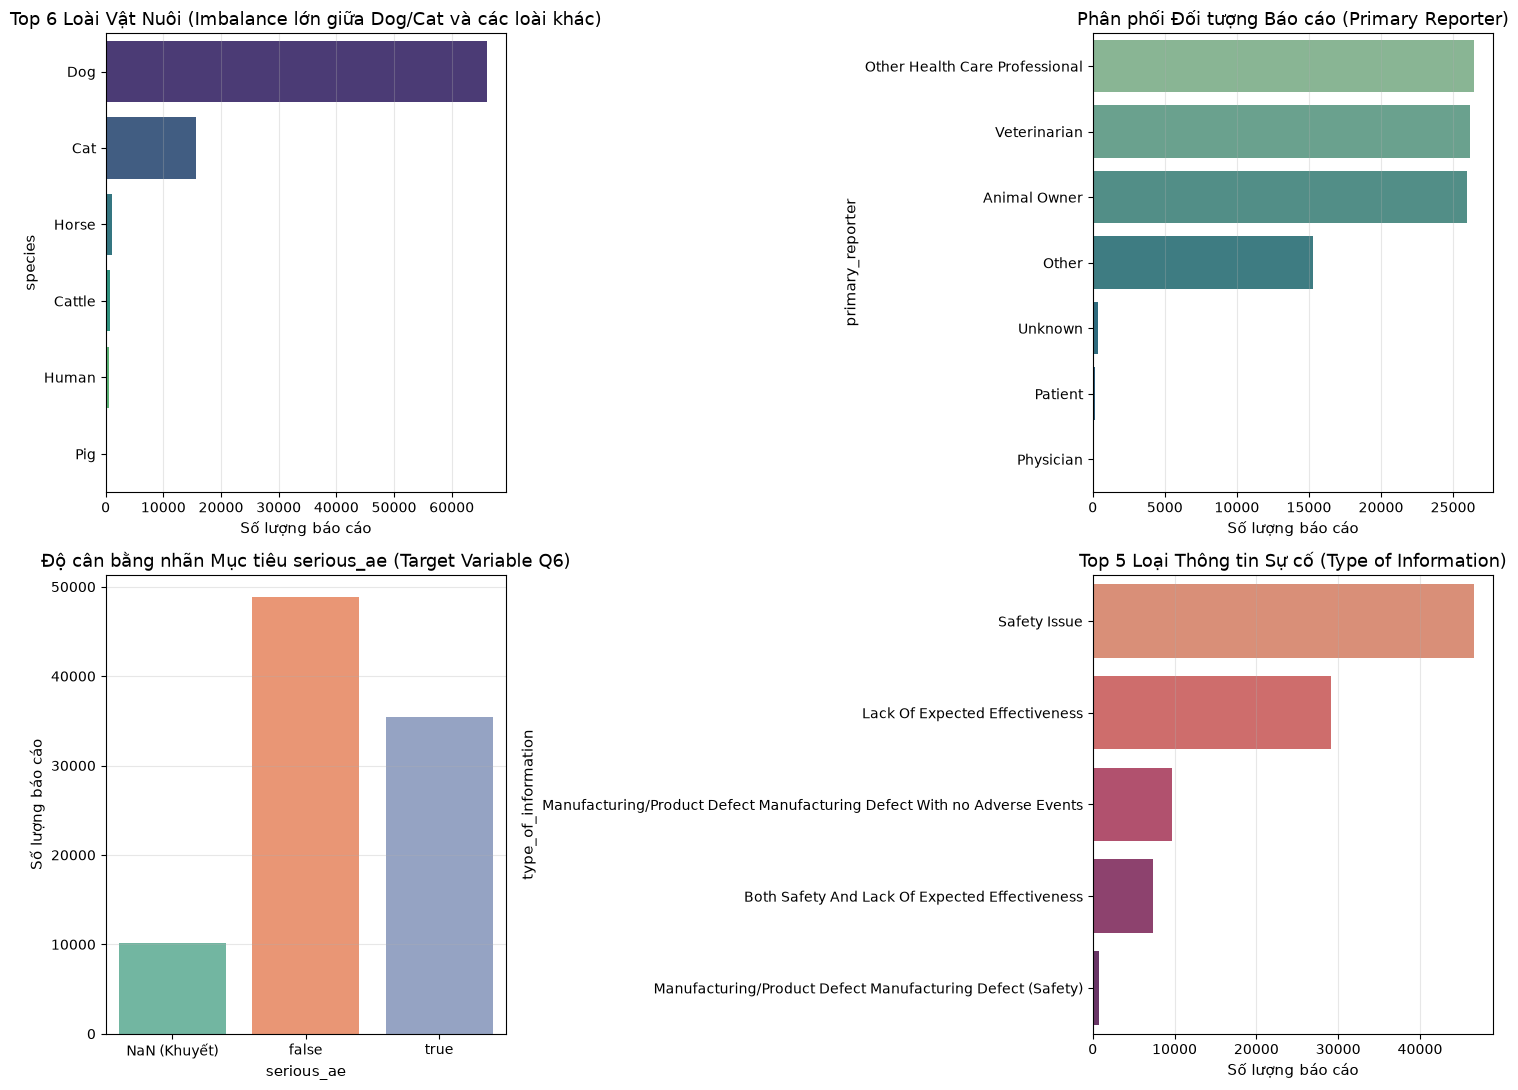

In [9]:
# 1. Thống kê Cardinality, Tỷ lệ khuyết và Tần suất cho các biến phân loại chính trong reports_df
cat_cols = ['species', 'gender', 'primary_reporter', 'type_of_information', 'serious_ae', 'treated_for_ae']

summary_records = []
for col in cat_cols:
    s = reports_df[col]
    n_unique = s.nunique(dropna=True)
    missing_cnt = s.isna().sum()
    top_val = s.value_counts(dropna=True).index[0] if n_unique > 0 else 'N/A'
    top_cnt = s.value_counts(dropna=True).iloc[0] if n_unique > 0 else 0
    top_pct = (top_cnt / len(s)) * 100
    summary_records.append({
        'Tên cột': col,
        'Số giá trị duy nhất (Cardinality)': n_unique,
        'Giá trị phổ biến nhất (Mode)': top_val,
        'Tần suất Mode': f'{top_cnt:,}',
        'Tỷ lệ Mode (%)': f'{top_pct:.2f}%',
        'Số lượng khuyết (NaN)': f'{missing_cnt:,}',
        'Tỷ lệ khuyết (%)': f'{(missing_cnt / len(s)) * 100:.2f}%'
    })

cat_summary_df = pd.DataFrame(summary_records)
print('=== TỔNG QUAN BIẾN PHÂN LOẠI CẤP BÁO CÁO (REPORTS) ===')
display(cat_summary_df)

# 2. Kiểm tra độ cân bằng nhãn mục tiêu serious_ae (Target Variable cho Q6 - ML)
print('\n=== ĐỘ CÂN BẰNG NHÃN MỤC TIÊU (serious_ae Balance) ===')
serious_counts = reports_df['serious_ae'].value_counts(dropna=False)
serious_pct = reports_df['serious_ae'].value_counts(dropna=False, normalize=True) * 100
serious_balance_df = pd.DataFrame({'Số lượng': serious_counts, 'Tỷ lệ (%)': serious_pct.round(2)})
display(serious_balance_df)

# 3. Kiểm tra nhãn không nhất quán (Case Sensitivity / Whitespace) ở các cột phân loại
print('\n=== KIỂM TRA NHÃN KHÔNG NHẤT QUÁN (Inconsistent Labels) ===')
for col in ['species', 'gender', 'primary_reporter', 'type_of_information']:
    vals = reports_df[col].dropna().unique()
    lower_map = {}
    for v in vals:
        lower_map.setdefault(v.lower().strip(), []).append(v)
    inconsistencies = {k: v for k, v in lower_map.items() if len(v) > 1}
    if inconsistencies:
        print(f'- Phát hiện nhãn không nhất quán ở cột {col}: {inconsistencies}')
    else:
        print(f'- Cột {col}: Không phát hiện xung đột chữ hoa/thường hay khoảng trắng dư thừa.')

# 4. Nhận diện các Category hiếm (Rare Categories < 1% tổng số mẫu)
print('\n=== CÁC DANH MỤC HIẾM TRONG SPECIES (< 1% -> Gom vào "Other") ===')
species_counts = reports_df['species'].value_counts(dropna=True)
rare_species = species_counts[species_counts / len(reports_df) < 0.01]
print(f'Tổng số loài hiếm (< 1%): {len(rare_species)} loài ({rare_species.sum():,} bản ghi, chiếm {(rare_species.sum()/len(reports_df))*100:.2f}%)')
print('Ví dụ 10 loài hiếm tiêu biểu:', list(rare_species.index[:10]))

# 5. Trực quan hóa phân phối biến phân loại và độ mất cân bằng lớp
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 5.1. Top loài vật nuôi (chuẩn Seaborn >= 0.13: truyền hue=y và legend=False)
top_species = reports_df['species'].value_counts().head(6)
sns.barplot(x=top_species.values, y=top_species.index, hue=top_species.index, legend=False, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Top 6 Loài Vật Nuôi (Imbalance lớn giữa Dog/Cat và các loài khác)')
axes[0, 0].set_xlabel('Số lượng báo cáo')

# 5.2. Đối tượng báo cáo chính
top_reporters = reports_df['primary_reporter'].value_counts()
sns.barplot(x=top_reporters.values, y=top_reporters.index, hue=top_reporters.index, legend=False, ax=axes[0, 1], palette='crest')
axes[0, 1].set_title('Phân phối Đối tượng Báo cáo (Primary Reporter)')
axes[0, 1].set_xlabel('Số lượng báo cáo')

# 5.3. Độ cân bằng nhãn mục tiêu serious_ae
serious_plot_data = reports_df.fillna({'serious_ae': 'NaN (Khuyết)'})
sns.countplot(data=serious_plot_data, x='serious_ae', hue='serious_ae', legend=False, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Độ cân bằng nhãn Mục tiêu serious_ae (Target Variable Q6)')
axes[1, 0].set_ylabel('Số lượng báo cáo')

# 5.4. Loại thông tin biến cố
top_info = reports_df['type_of_information'].value_counts().head(5)
sns.barplot(x=top_info.values, y=top_info.index, hue=top_info.index, legend=False, ax=axes[1, 1], palette='flare')
axes[1, 1].set_title('Top 5 Loại Thông tin Sự cố (Type of Information)')
axes[1, 1].set_xlabel('Số lượng báo cáo')

plt.tight_layout()
plt.show()


### 2.4. Phân tích Dữ liệu Khuyết (Missing Data Analysis)
- Số lượng và tỷ lệ % giá trị khuyết trên từng cột.
- Đánh giá cơ chế khuyết (MCAR / MAR / MNAR): ví dụ `onset_date`, `weight`, hoặc `serious_ae` bị khuyết có phụ thuộc vào `primary_reporter` hay `type_of_information` không?
- Chiến lược xử lý cho từng cột (Drop, Impute hay tách thành nhóm `'Unknown'` riêng).

In [ ]:
# TODO [Giai đoạn 2]: Bảng tổng hợp tỷ lệ missing và biểu đồ trực quan hóa mẫu khuyết


### 2.5. Mối quan hệ sơ bộ giữa các biến (Relationships)
- Tương quan giữa các biến số và bảng chéo (cross-tabulations) giữa các tổ hợp quan trọng (`species` $\times$ `serious_ae`, `type_of_information` $\times$ `primary_reporter`, xu hướng số lượng báo cáo theo quý từ 2025Q1 đến 2026).

In [ ]:
# TODO [Giai đoạn 2]: Ma trận tương quan và cross-tabulation sơ bộ


### 2.6. Tổng kết Khám phá Dữ liệu & Kế hoạch Tiền xử lý (EDA Summary & Preprocessing Plan)
1. **3–5 Quan sát cốt lõi (Key Observations):** *(Cập nhật sau khi chạy dữ liệu)*
2. **Các vấn đề chất lượng dữ liệu nghiêm trọng (Serious Data Quality Issues):** *(Đơn vị tuổi/cân nặng hỗn hợp, cấu trúc 1-nhiều lồng nhau, tỷ lệ khuyết ở các trường tùy chọn...)*
3. **Kế hoạch Tiền xử lý chuẩn hóa (Preprocessing Plan):** Lưu các bảng đã làm sạch vào `data/processed/` để sử dụng thống nhất cho Notebook 02 và Notebook 03.

In [ ]:
# TODO [Giai đoạn 2]: Lưu dữ liệu đã chuẩn hóa cơ bản vào ../data/processed/
